Original Data Shape: (300, 2)

LINEAR SVM - 2D
              precision    recall  f1-score   support

           0       0.56      0.43      0.48       150
           1       0.54      0.66      0.59       150

    accuracy                           0.54       300
   macro avg       0.55      0.54      0.54       300
weighted avg       0.55      0.54      0.54       300



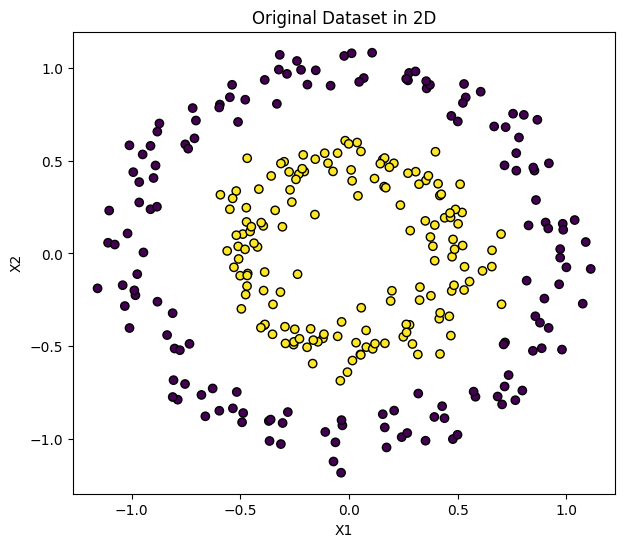

Transformed Data Shape: (300, 3)


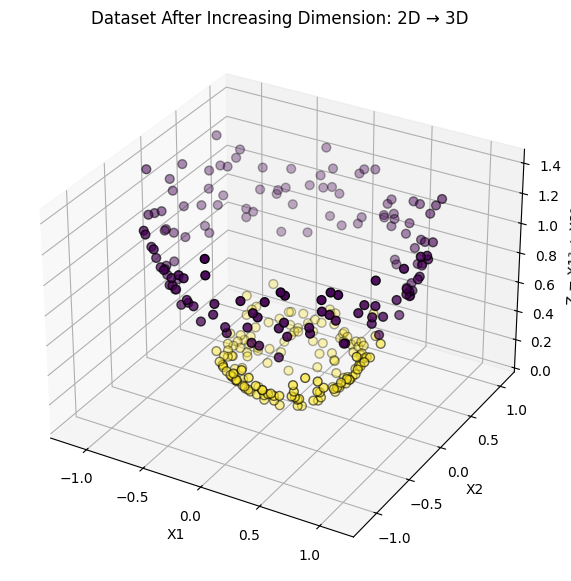


LINEAR SVM - 3D
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       150
           1       1.00      1.00      1.00       150

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300

Hyperplane equation:
-0.017 X1 + -0.044 X2 + -4.733 Z + 2.774 = 0


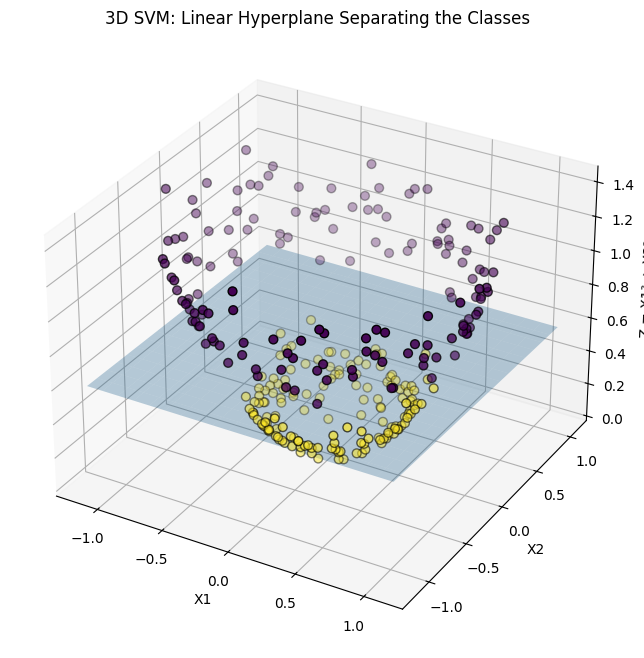


RBF KERNEL SVM
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       150
           1       1.00      1.00      1.00       150

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300


POLYNOMIAL KERNEL SVM
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       150
           1       1.00      1.00      1.00       150

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from mpl_toolkits.mplot3d import Axes3D


X, y = make_circles(
    n_samples=300,
    factor=0.5,
    noise=0.08,
    random_state=42
)

print("Original Data Shape:", X.shape)



linear_model = SVC(kernel="linear")

linear_model.fit(X, y)

y_pred_linear = linear_model.predict(X)

print("\n===================================")
print("LINEAR SVM - 2D")


print(classification_report(y, y_pred_linear))


plt.figure(figsize=(7, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    edgecolors="black"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Original Dataset in 2D")

plt.show()



# TRANSFORM 2D → 3D


X1 = X[:, 0]
X2 = X[:, 1]

Z = X1**2 + X2**2

X_3D = np.column_stack((X1, X2, Z))

print("Transformed Data Shape:", X_3D.shape)


# ============================================================
# 5. VISUALIZE DATA IN 3D


fig = plt.figure(figsize=(9, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X1,
    X2,
    Z,
    c=y,
    s=40,
    edgecolors="black"
)

ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("Z = X1² + X2²")

ax.set_title("Dataset After Increasing Dimension: 2D → 3D")

plt.show()


# ============================================================
# LINEAR SVM IN 3D


svm_3d = SVC(kernel="linear")

svm_3d.fit(X_3D, y)

y_pred_3d = svm_3d.predict(X_3D)

print("\n===================================")
print("LINEAR SVM - 3D")
print("===================================")

print(classification_report(y, y_pred_3d))


w = svm_3d.coef_[0]
b = svm_3d.intercept_[0]

print("Hyperplane equation:")

print(
    f"{w[0]:.3f} X1 + "
    f"{w[1]:.3f} X2 + "
    f"{w[2]:.3f} Z + "
    f"{b:.3f} = 0"
)


fig = plt.figure(figsize=(10, 8))

ax = fig.add_subplot(111, projection="3d")

# Plot points

ax.scatter(
    X1,
    X2,
    Z,
    c=y,
    s=40,
    edgecolors="black"
)


# Create plane

x1_range = np.linspace(
    X1.min(),
    X1.max(),
    20
)

x2_range = np.linspace(
    X2.min(),
    X2.max(),
    20
)

X1_plane, X2_plane = np.meshgrid(
    x1_range,
    x2_range
)


Z_plane = (
    -(w[0] * X1_plane +
      w[1] * X2_plane +
      b)
    / w[2]
)


# Plot hyperplane

ax.plot_surface(
    X1_plane,
    X2_plane,
    Z_plane,
    alpha=0.3
)


ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("Z = X1² + X2²")

ax.set_title(
    "3D SVM: Linear Hyperplane Separating the Classes"
)

plt.show()


# ============================================================
# 9. RBF KERNEL SVM


rbf_model = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

rbf_model.fit(X, y)

y_pred_rbf = rbf_model.predict(X)

print("\n===================================")
print("RBF KERNEL SVM")


print(classification_report(y, y_pred_rbf))


# ============================================================
# 10. POLYNOMIAL KERNEL SVM


poly_model = SVC(
    kernel="poly",
    degree=2,
    C=1
)

poly_model.fit(X, y)

y_pred_poly = poly_model.predict(X)

print("\n===================================")
print("POLYNOMIAL KERNEL SVM")


print(classification_report(y, y_pred_poly))